<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/Actividad_2_integral_estoc%C3%A1stica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<div align="center">

# <font color="#176B58">Actividad 2. Integral estocástica</font>

**Materia:** Simulación II

**Nombre:** Karla Michelle Soriano Sánchez

</div>





**Ejercicio 1.** Pruebe que

$$
E\left[\int_0^t W_s^2\,ds\right]=\frac{t^2}{2}
$$

y

$$
\operatorname{Var}\left[\int_0^t W_s^2\,ds\right]
=\frac{t^4}{3}.
$$

**Sugerencia:** Aplique el procedimiento del ejemplo visto en clase y pruebe primero que

$$
\operatorname{Cov}(W_u^2,W_v^2)=2\min\{u,v\}^2.
$$

**Ejercicio 2.** Compruebe por simulación los resultados del ejercicio anterior, para $t=1$.



Para comprobar los resultados del ejercicio 1, realizaremos una simulación del movimiento browniano estándar y aproximaremos la integral

$$
I_1=\int_0^1 W_s^2\,ds.
$$

De la solución analítica sabemos que

$$
E[I_t]=\frac{t^2}{2},
\qquad
\operatorname{Var}(I_t)=\frac{t^4}{3}.
$$

Sustituyendo $t=1$, obtenemos los valores teóricos:

$$
E[I_1]=\frac{1}{2}=0.5,
$$

$$
\operatorname{Var}(I_1)=\frac{1}{3}\approx0.333333.
$$

In [31]:

import random as r
import numpy as np
import matplotlib.pyplot as plt


### <font color="#176B58"> Generación del movimiento browniano</font>

Utilizamos la función `brown(T, n)` desarrollada anteriormente en clase, que genera una trayectoria del movimiento browniano estándar mediante

$$
W_{i+1}=W_i+\sqrt{\Delta t}\,Z_i,
$$

donde

$$
\Delta t=\frac{T}{n},
\qquad Z_i\sim N(0,1),
\qquad W_0=0.
$$

La función devuelve los $n+1$ valores de la trayectoria, incluyendo el valor inicial.

In [32]:

def brown(T, n):
    """Genera una trayectoria browniana estándar en [0, T] con n pasos."""

    dt = T / n       # Tamaño del paso de tiempo
    W_0 = 0          # Valor inicial del movimiento browniano
    lista = [W_0]    # Guardamos la trayectoria comenzando en cero

    for i in range(n):
        dw = r.gauss(0, 1)              # Generamos una normal estándar
        W_1 = W_0 + np.sqrt(dt) * dw     # Calculamos el nuevo valor
        lista.append(W_1)               # Guardamos el valor
        W_0 = W_1                       # Actualizamos el valor anterior

    return lista


### <font color="#176B58"> Aproximación de la integral</font>

Para cada trayectoria, aproximaremos la integral

$$
I_1=\int_0^1 W_s^2\,ds
$$

mediante una suma de Riemann, siguiendo el procedimiento visto en clase.

Dividimos el intervalo $[0,1]$ en $n=1000$ partes iguales:

$$
\Delta t=\frac{1}{1000}=0.001.
$$

Utilizando los extremos izquierdos de cada intervalo, la aproximación es

$$
I_1\approx\sum_{i=0}^{n-1}W_{t_i}^2\Delta t.
$$

De esta manera, obtenemos un valor aproximado de la integral para cada trayectoria generada.

In [33]:

def integral_brown(T, n):
    """
    Aproxima la integral de W(s)^2 respecto al tiempo,
    utilizando una suma de Riemann.
    """

    W = brown(T, n)  # Generamos una trayectoria
    dt = T / n       # Tamaño del paso

    I = 0

    for i in range(n):
        I += W[i]**2 * dt  # Sumamos los términos de Riemann

    return I


### <font color="#176B58"> Simulación y cálculo de resultados</font>

Realizaremos $N=10\,000$ simulaciones independientes. En cada una se genera una trayectoria browniana y se calcula el valor aproximado de la integral.

Los valores obtenidos serán

$$
I_1^{(1)},I_1^{(2)},\ldots,I_1^{(N)}.
$$

Con ellos calcularemos la media muestral:

$$
\overline{I}_1=\frac{1}{N}\sum_{j=1}^{N}I_1^{(j)},
$$

y la varianza muestral:

$$
S_I^2=\frac{1}{N-1}
\sum_{j=1}^{N}\left(I_1^{(j)}-\overline{I}_1\right)^2.
$$

Finalmente, calcularemos los errores absolutos para comparar las estimaciones con los valores teóricos.

In [34]:

# Parámetros de la simulación
T = 1
n = 1000
N = 10000

# Calculamos la integral para cada trayectoria
integrales = []

for j in range(N):
    # Calculamos y guardamos su integral
    I = integral_brown(T, n)
    integrales.append(I)

# Media y varianza simuladas
media_sim = np.mean(integrales)
var_sim = np.var(integrales, ddof=1)

# Valores teóricos
media_teo = T**2 / 2
var_teo = T**4 / 3

# Errores absolutos
error_media = abs(media_sim - media_teo)
error_var = abs(var_sim - var_teo)

# Presentación de resultados
print("RESULTADOS DE LA SIMULACIÓN")
print(f"Simulaciones: {N}")
print(f"Pasos por trayectoria: {n}\n")

print(f"Media teórica:       {media_teo:.6f}")
print(f"Media simulada:      {media_sim:.6f}")
print(f"Error absoluto:      {error_media:.6f}\n")

print(f"Varianza teórica:    {var_teo:.6f}")
print(f"Varianza simulada:   {var_sim:.6f}")
print(f"Error absoluto:      {error_var:.6f}")

RESULTADOS DE LA SIMULACIÓN
Simulaciones: 10000
Pasos por trayectoria: 1000

Media teórica:       0.500000
Media simulada:      0.491254
Error absoluto:      0.008746

Varianza teórica:    0.333333
Varianza simulada:   0.337753
Error absoluto:      0.004420



### <font color="#176B58"> Representación gráfica</font>

Para observar los resultados, construiremos un histograma de los 10,000 valores simulados de la integral.

También señalaremos la media teórica y la media simulada mediante líneas verticales, con el propósito de comparar sus valores.

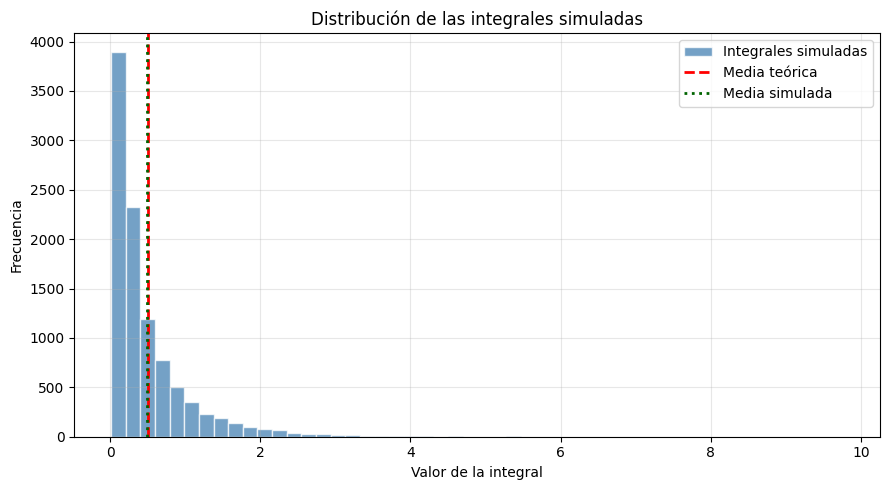

In [35]:

# Histograma de los valores simulados
plt.figure(figsize=(9, 5))

plt.hist(integrales, bins=50, color="steelblue",
         edgecolor="white", alpha=0.75,
         label="Integrales simuladas")

# Medias teórica y simulada
plt.axvline(media_teo, color="red", linestyle="--",
            linewidth=2, label="Media teórica")

plt.axvline(media_sim, color="darkgreen", linestyle=":",
            linewidth=2, label="Media simulada")

# Presentación de la gráfica
plt.title("Distribución de las integrales simuladas")
plt.xlabel("Valor de la integral")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Se realizaron 10,000 simulaciones del movimiento browniano estándar para aproximar la integral

$$
I_1=\int_0^1 W_s^2\,ds.
$$

La media y la varianza simuladas se compararon con los valores teóricos de $0.5$ y $1/3$, respectivamente.

Las diferencias se evaluaron mediante errores absolutos. Estas pueden deberse a la variabilidad aleatoria de las trayectorias y a la aproximación numérica de la integral.

### <font color="#176B58">Conclusión</font>

La simulación permite comprobar numéricamente los resultados del ejercicio 1 mediante la comparación de la media y la varianza simuladas con sus valores teóricos.